# 01 · Exploratory data analysis

**Goal of this notebook:** load the Hillstrom email experiment, check data quality, measure the average effect of each email (with confidence intervals), look at the spend distribution, confirm that randomization worked, and create the single train/test split used by every later notebook.

**The data in one sentence:** 64,000 past customers were randomly split into three equal groups: one got a men's merchandise email, one a women's email, one no email (control). Two weeks later the shop recorded whether each customer visited the website, bought something (conversion), and how much they spent.

In [1]:
# Make `src` importable from the notebooks folder (works on Windows and macOS)
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src.config import *
FIG_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_json(obj, name):
    (RESULTS_DIR / name).write_text(json.dumps(obj, indent=2, default=float))

## 1. Load the data
`load_hillstrom()` calls `sklift.datasets.fetch_hillstrom` once per outcome (visit, conversion, spend), joins them, and caches the file in `data/raw/` so later runs work offline.

In [2]:
from src.preprocessing import load_hillstrom, make_split, balance_table, chi_square_table, add_arm, FEATURES, OUTCOMES
from src.evaluation import diff_in_means

df = add_arm(load_hillstrom())
print(df.shape)
df.head()

(64000, 13)


,recency,history,mens,womens,newbie,zip_code,channel,history_segment,segment,visit,conversion,spend,arm
0,10,142.4400,1,0,0,Surburban,Phone,2) $100 - $200,Womens E-Mail,0,0,0.0000,2
1,6,329.0800,1,1,1,Rural,Web,3) $200 - $350,No E-Mail,0,0,0.0000,0
2,7,180.6500,0,1,1,Surburban,Web,2) $100 - $200,Womens E-Mail,0,0,0.0000,2
3,9,675.8300,1,0,1,Rural,Web,5) $500 - $750,Mens E-Mail,0,0,0.0000,1
4,2,45.3400,1,0,0,Urban,Web,1) $0 - $100,Womens E-Mail,0,0,0.0000,2


## 2. Data quality checks
Missing values, duplicates, value ranges, and the size of each arm.

In [3]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "n_unique": df.nunique()})
print("Duplicate rows:", df.duplicated().sum())
display(quality)
display(df[["recency", "history", "spend"]].describe().T)
print(df["segment"].value_counts())

Duplicate rows: 6562


,dtype,missing,n_unique
recency,int64,0,12
history,float64,0,34833
mens,int64,0,2
womens,int64,0,2
newbie,int64,0,2
zip_code,str,0,3
channel,str,0,3
history_segment,str,0,7
segment,str,0,3
visit,int64,0,2


,count,mean,std,min,25%,50%,75%,max
recency,"64,000.0000",5.7637,3.5076,1.0000,2.0000,6.0000,9.0000,12.0000
history,"64,000.0000",242.0857,256.1586,29.9900,64.6600,158.1100,325.6575,"3,345.9300"
spend,"64,000.0000",1.0509,15.0364,0.0000,0.0000,0.0000,0.0000,499.0000


segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


**About the "duplicate" rows:** the dataset has no customer ID and its features are coarse (recency in months, 0/1 flags, 3 zip types, 3 channels), so different customers can share exactly the same values and outcomes. These rows are **not** export errors, so we keep them. There are no missing values.

### Why we drop `history_segment`
`history_segment` is just `history` (dollars spent last year) cut into 7 bins. The check below shows every `history` value falls inside the range written in its bin label, so the binned column adds no new information. Tree models can find the best cut points themselves, so we keep the precise `history` and drop the bins (keeping both would count the same signal twice).

In [4]:
rng = df.groupby("history_segment")["history"].agg(["min", "max", "count"])
display(rng)

,min,max,count
history_segment,,,
1) $0 - $100,29.9900,99.9900,22970
2) $100 - $200,100.0000,199.9800,14254
3) $200 - $350,200.0000,349.9600,12289
4) $350 - $500,350.0100,499.9500,6409
5) $500 - $750,500.0000,749.7900,4911
"6) $750 - $1,000",750.0100,999.7500,1859
"7) $1,000 +","1,000.1500","3,345.9300",1308


## 3. Outcomes by arm and the average treatment effect (ATE)
Because customers were assigned at random, the difference between an email arm and the control arm is an unbiased estimate of the **average** effect of that email. The 95% confidence interval (CI) shows how precise the estimate is.

In [5]:
rates = df.groupby("segment")[OUTCOMES].mean()
display(rates)

def ate_table(data):
    rows = []
    for arm in (1, 2):
        for out in OUTCOMES:
            d = diff_in_means(data.loc[data.arm == arm, out], data.loc[data.arm == 0, out])
            base = data.loc[data.arm == 0, out].mean()
            rows.append({"arm": ARMS[arm], "outcome": out, "control_mean": base, "ATE": d["diff"],
                         "ci_lo": d["lo"], "ci_hi": d["hi"], "relative_lift": d["diff"] / base})
    return pd.DataFrame(rows)

ate = ate_table(df)
display(ate)

,visit,conversion,spend
segment,,,
Mens E-Mail,0.1828,0.0125,1.4226
No E-Mail,0.1062,0.0057,0.6528
Womens E-Mail,0.1514,0.0088,1.0772


,arm,outcome,control_mean,ATE,ci_lo,ci_hi,relative_lift
0,Mens E-Mail,visit,0.1062,0.0766,0.0700,0.0832,0.7214
1,Mens E-Mail,conversion,0.0057,0.0068,0.0050,0.0086,1.1884
2,Mens E-Mail,spend,0.6528,0.7698,0.4851,1.0545,1.1793
3,Womens E-Mail,visit,0.1062,0.0452,0.0389,0.0516,0.4261
4,Womens E-Mail,conversion,0.0057,0.0031,0.0015,0.0047,0.5433
5,Womens E-Mail,spend,0.6528,0.4244,0.1690,0.6799,0.6502


Spend is mostly zeros with a long tail, so the normal-formula CI above may be unreliable for spend. We double-check it with a bootstrap (resample customers 1,000 times and take the middle 95% of the results).

In [6]:
rng_ = np.random.default_rng(SEED)
boot_rows = []
for arm in (1, 2):
    s_t, s_c = df.loc[df.arm == arm, "spend"].to_numpy(), df.loc[df.arm == 0, "spend"].to_numpy()
    b = [rng_.choice(s_t, len(s_t)).mean() - rng_.choice(s_c, len(s_c)).mean() for _ in range(1000)]
    boot_rows.append({"arm": ARMS[arm], "ATE_spend": s_t.mean() - s_c.mean(),
                      "boot_lo": np.percentile(b, 2.5), "boot_hi": np.percentile(b, 97.5)})
spend_boot = pd.DataFrame(boot_rows)
display(spend_boot)

,arm,ATE_spend,boot_lo,boot_hi
0,Mens E-Mail,0.7698,0.4806,1.0545
1,Womens E-Mail,0.4244,0.1461,0.6853


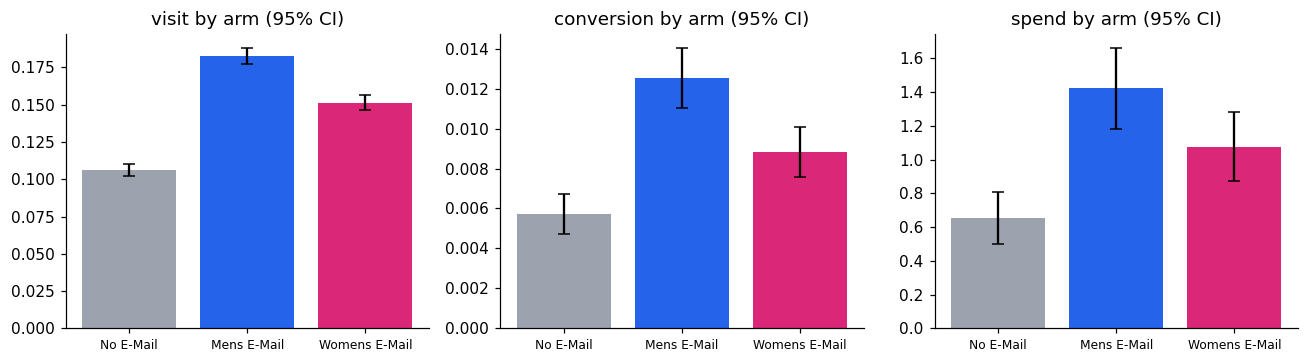

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
colors = {"No E-Mail": "#9CA3AF", "Mens E-Mail": "#2563EB", "Womens E-Mail": "#DB2777"}
for ax, out in zip(axes, OUTCOMES):
    m = df.groupby("segment")[out].agg(["mean", "sem"]).loc[list(colors)]
    ax.bar(m.index, m["mean"], yerr=1.96 * m["sem"], color=list(colors.values()), capsize=4)
    ax.set_title(f"{out} by arm (95% CI)"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "01_outcomes_by_arm.png", bbox_inches="tight"); plt.show()

## 4. Spend distribution
How many customers spend anything at all, and what does spend look like among buyers?

Share of customers with zero spend: 99.10%
Conversion rate overall: 0.90%  |  buyers: 578


count   578.0000
mean    116.3635
std     107.8715
min      29.9900
25%      32.2725
50%      80.7950
75%     153.3500
max     499.0000
Name: spend, dtype: float64

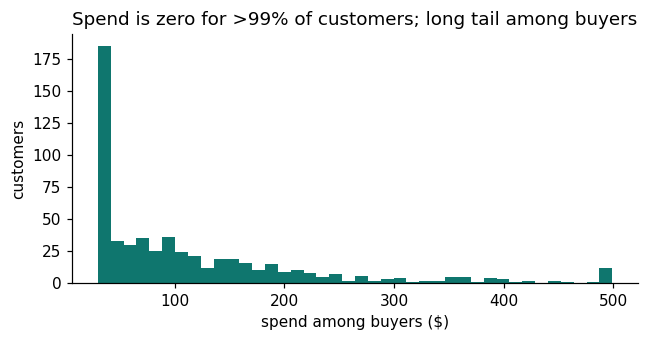

In [8]:
share_zero = (df.spend == 0).mean()
buyers = df.loc[df.spend > 0, "spend"]
print(f"Share of customers with zero spend: {share_zero:.2%}")
print(f"Conversion rate overall: {df.conversion.mean():.2%}  |  buyers: {len(buyers)}")
display(buyers.describe())
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(buyers, bins=40, color="#0F766E")
ax.set_xlabel("spend among buyers ($)"); ax.set_ylabel("customers"); ax.set_title("Spend is zero for >99% of customers; long tail among buyers")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_spend_distribution.png", bbox_inches="tight"); plt.show()

## 5. Did randomization work? (balance check)
If the arms were truly random, customer features should look the same in every arm.
* **Standardized mean difference (SMD)**: difference in means divided by the pooled standard deviation. Rule of thumb: |SMD| < 0.1 means balanced.
* **Chi-square test**: tests whether the distribution of a categorical feature depends on the arm. A large p-value (> 0.05) means no evidence of imbalance. With many tests, one small p-value can appear by chance.

Largest |SMD|: 0.0164


,feature,SMD Mens E-Mail vs control,SMD Womens E-Mail vs control
0,recency,0.0068,0.0052
1,history,0.0076,0.0065
2,mens,-0.0046,-0.0086
3,womens,0.0076,0.0049
4,newbie,-0.0009,0.0026
5,zip_code_Rural,0.0137,0.0040
6,zip_code_Surburban,-0.0117,-0.0011
7,zip_code_Urban,0.0020,-0.0018
8,channel_Multichannel,-0.0042,-0.0053
9,channel_Phone,-0.0083,0.0086


,feature,chi2,dof,p_value
0,history_segment,13.1533,12,0.3580
1,zip_code,2.8719,4,0.5795
2,channel,3.6324,4,0.4580
3,mens,0.7960,2,0.6717
4,womens,0.6325,2,0.7289
5,newbie,0.1369,2,0.9339


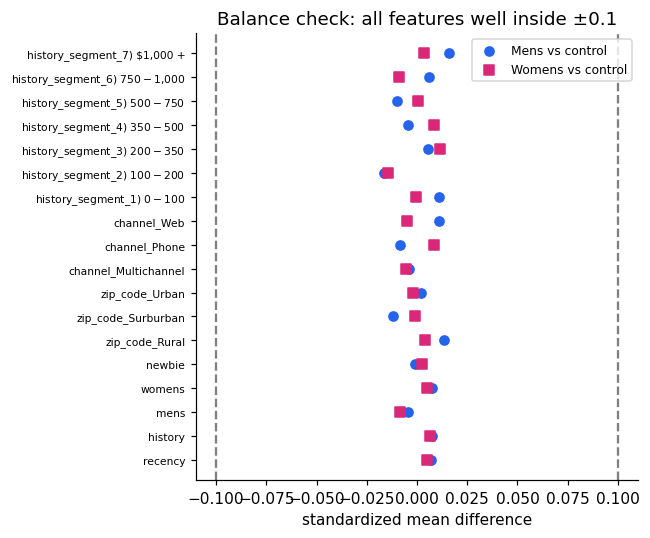

In [9]:
bal = balance_table(df)
chi = chi_square_table(df)
print("Largest |SMD|:", bal.iloc[:, 1:].abs().max().max().round(4))
display(bal)
display(chi)
fig, ax = plt.subplots(figsize=(6, 5))
y = np.arange(len(bal))
ax.scatter(bal.iloc[:, 1], y, label="Mens vs control", color="#2563EB")
ax.scatter(bal.iloc[:, 2], y, label="Womens vs control", color="#DB2777", marker="s")
ax.axvline(-0.1, ls="--", c="grey"); ax.axvline(0.1, ls="--", c="grey")
ax.set_yticks(y); ax.set_yticklabels(bal.feature, fontsize=7); ax.set_xlabel("standardized mean difference")
ax.set_title("Balance check: all features well inside ±0.1"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "01_balance_smd.png", bbox_inches="tight"); plt.show()

## 6. Train / Validation / Test Split

We split the 64,000 customers into **60% training, 20% validation, and 20% testing**, stratified by treatment arm × visit outcome, using random seed 42.

- **Training:** Used to train the machine learning models.
- **Validation:** Used to select the best targeting threshold and tune decisions.
- **Testing:** Reserved for the final unbiased evaluation.

All three datasets are saved in `data/processed/` and reused across notebooks.

In [10]:

train, validation, test = make_split(
    df.drop(columns="arm"),
    refresh=True
)

check = pd.DataFrame({
    "train_share": train.groupby("segment").size() / len(train),
    "validation_share": validation.groupby("segment").size() / len(validation),
    "test_share": test.groupby("segment").size() / len(test),

    "train_visit": train.groupby("segment").visit.mean(),
    "validation_visit": validation.groupby("segment").visit.mean(),
    "test_visit": test.groupby("segment").visit.mean()
})

print("Training customers:", len(train))
print("Validation customers:", len(validation))
print("Testing customers:", len(test))

display(check)


Training customers: 38400
Validation customers: 12800
Testing customers: 12800


,train_share,validation_share,test_share,train_visit,validation_visit,test_visit
segment,,,,,,
Mens E-Mail,0.3329,0.3330,0.3329,0.1827,0.1828,0.1828
No E-Mail,0.3329,0.3330,0.3329,0.1062,0.1063,0.1061
Womens E-Mail,0.3342,0.3341,0.3342,0.1514,0.1513,0.1515


In [11]:
save_json({"n_rows": len(df), "n_train": len(train), "n_validation": len(validation), "n_test": len(test),
           "duplicates": int(df.duplicated().sum()), "missing": int(df.isna().sum().sum()),
           "rates_by_arm": rates.reset_index().to_dict("records"),
           "ate": ate.to_dict("records"), "spend_bootstrap": spend_boot.to_dict("records"),
           "share_zero_spend": share_zero, "conversion_rate": df.conversion.mean(), "visit_rate": df.visit.mean(),
           "n_buyers": int(len(buyers)), "buyer_spend_mean": buyers.mean(), "buyer_spend_median": buyers.median(),
           "max_abs_smd": float(bal.iloc[:, 1:].abs().max().max()), "chi_square": chi.to_dict("records")},
          "01_eda.json")
print("saved")

saved


## What we found
* **Data quality:** 64,000 rows, no missing values; identical rows are distinct customers with the same coarse profile (kept).
* **Both emails work on average.** Visit rate: control 10.6%, men's email 18.3% (+7.7 points, 95% CI 7.0 to 8.3), women's email 15.1% (+4.5 points, CI 3.9 to 5.2).
* **Conversion is rare:** 0.90% overall (578 buyers out of 64,000). Effects on conversion and spend are positive but much noisier: men's email +$0.77 spend per customer (bootstrap CI $0.48 to $1.05), women's +$0.42 (CI $0.15 to $0.69).
* **Spend is zero for 99.1% of customers**; buyers spend $116 on average (median $81). This is why we use bootstrap CIs for spend.
* **Randomization worked:** the largest |SMD| across all features is 0.016 (far below 0.1) and no chi-square test is significant (all p > 0.35).
* **Why this matters for the project:** the average effect is positive, but the question is *who* drives it. With only ~0.9% converting, learning individual effects on conversion would be very noisy, so `visit` (14.7% base rate) is our primary outcome.
* **Data splitting:** The dataset is divided into 38,400 training customers, 12,800 validation customers, and 12,800 testing customers. Validation is used for model and threshold selection, while testing is reserved for final evaluation.